# Full-throttle speed loss: 2025 vs 2026 qualifying, paired by straight

The same pipeline (`flatout.run_session`, same cleaning and QC) runs on 2025 qualifying at every circuit that has also hosted 2026 qualifying so far. Circuits are matched by OpenF1 `circuit_key`, not by event name; Madrid (new in 2026) and the 2026 Sepang round have no 2025 counterpart. A straight is compared when it appears in both years (same circuit, corner label and main-straight flag) with >= 10 clean drivers in each year.

**Caveats.** 2025 cars differ in many ways (MGU-H, 120 kW MGU-K, DRS in qualifying, aerodynamics), so year differences reflect the whole 2026 package, not one rule. Pooling 2026 across PUs is justified by the season result (no detectable PU difference), which is not proof that none exists. C5.2.8 values are not computed for 2025 (a 2026 rule). Descriptive only.

In [1]:
import json
import re
from pathlib import Path

import fastf1
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from flatout import OPENF1_CACHE, FIG, PU_2025, caption, load_quali, openf1_session_key, run_session, to_seconds

MIN_CLEAN_DRIVERS = 10
OUT25, OUT26 = Path("data/season2025"), Path("data/season")
OUT25.mkdir(parents=True, exist_ok=True)


def circuit_of(year, rnd):
    """(OpenF1 session_key, circuit_key, circuit_short_name) of an event's main Qualifying."""
    key = openf1_session_key(year, rnd)
    ses = pd.DataFrame(json.loads((OPENF1_CACHE / f"sessions_{year}_qualifying.json").read_text()))
    row = ses[ses.session_key == key]
    return (key, int(row.circuit_key.iloc[0]), row.circuit_short_name.iloc[0]) if len(row) else (key, None, None)


qc26 = pd.read_csv(OUT26 / "qc_summary.csv")
qc26 = qc26[qc26.Status.eq("ok") & ~qc26.Event.eq("Bahrain Grand Prix")]  # 2026 Bahrain GP was held at Sepang: no 2025 counterpart
e26 = pd.DataFrame([dict(Round26=r.Round, Event26=r.Event, **dict(zip(["Key26", "Circuit", "CircuitName"], circuit_of(2026, r.Round))))
                    for r in qc26.itertuples()])
sch25 = fastf1.get_event_schedule(2025, include_testing=False)
sch25 = sch25[sch25.EventFormat.isin(["conventional", "sprint_qualifying"])]
e25 = pd.DataFrame([dict(Round25=r.RoundNumber, Event25=r.EventName, Location25=r.Location,
                         **dict(zip(["Key25", "Circuit", "_"], circuit_of(2025, r.RoundNumber)))) for r in sch25.itertuples()]).drop(columns="_")
pairs = e26.merge(e25, on="Circuit").sort_values("Round26").reset_index(drop=True)
print("2025 team -> PU:", PU_2025, "\n")
print(pairs[["CircuitName", "Round25", "Event25", "Round26", "Event26", "Key25", "Key26"]].to_string(index=False))
print("\n2026 sessions without a 2025 counterpart:", sorted(set(e26.Event26) - set(pairs.Event26)) or "none")

req         WARNING 	DEFAULT CACHE ENABLED! (56.0 KB) C:\Users\User\AppData\Local\Temp\fastf1


2025 team -> PU: {'Mercedes': 'Mercedes', 'McLaren': 'Mercedes', 'Williams': 'Mercedes', 'Aston Martin': 'Mercedes', 'Ferrari': 'Ferrari', 'Haas F1 Team': 'Ferrari', 'Kick Sauber': 'Ferrari', 'Red Bull Racing': 'Honda RBPT', 'Racing Bulls': 'Honda RBPT', 'Alpine': 'Renault'} 

      CircuitName  Round25               Event25  Round26               Event26  Key25  Key26
        Melbourne        1 Australian Grand Prix        1 Australian Grand Prix   9689  11230
         Shanghai        2    Chinese Grand Prix        2    Chinese Grand Prix   9994  11241
           Suzuka        3   Japanese Grand Prix        3   Japanese Grand Prix  10002  11249
            Miami        6      Miami Grand Prix        4      Miami Grand Prix  10029  11276
         Montreal       10   Canadian Grand Prix        5   Canadian Grand Prix   9959  11287
      Monte Carlo        8     Monaco Grand Prix        6     Monaco Grand Prix   9975  11295
        Catalunya        9    Spanish Grand Prix        7  Barce

## 2025 sessions (same cleaning and QC)

In [2]:
rows = []
for p in pairs.itertuples():
    row = dict(Round25=p.Round25, Event25=p.Event25, Circuit=p.CircuitName)
    try:
        tables, qc = run_session(2025, p.Round25, openf1_session=p.Key25)
        stem = OUT25 / f"{p.Round25:02d}_{re.sub(r'[^A-Za-z0-9]+', '_', p.Location25).strip('_').lower()}"
        to_seconds(tables["sectors"]).to_csv(f"{stem}_sectors.csv", index=False)
        to_seconds(tables["segments"]).to_csv(f"{stem}_segments.csv", index=False)
        tables["exclusions"].to_csv(f"{stem}_exclusions.csv", index=False)
        row.update(Status="ok", **{k: qc[k] for k in ["brake_source", "circuit_info", "push_laps", "push_lap_frozen_pct_mean"]})
    except Exception as e:
        row.update(Status=f"error: {type(e).__name__}: {e}")
    rows.append(row)
    print(f"2025 round {p.Round25:2d} {p.Event25:<28} {row['Status'][:70]}", flush=True)
qc25 = pd.DataFrame(rows)
qc25.to_csv(OUT25 / "qc_summary.csv", index=False)
qc25.rename(columns={"push_lap_frozen_pct_mean": "FreezeShare_pct"}).round(2)

core        WARNING 	Fixed incorrect tyre stint information for driver '4'


_api        WARNING 	Driver  2: Car data is incomplete!


_api        WARNING 	Driver  3: Car data is incomplete!


_api        WARNING 	Driver  8: Car data is incomplete!


_api        WARNING 	Driver  9: Car data is incomplete!


...

_api        WARNING 	Driver 81: Position data is incomplete!


_api        WARNING 	Driver 87: Position data is incomplete!


2025 round 17 Azerbaijan Grand Prix        ok


2025 round 18 Singapore Grand Prix         ok


,Round25,Event25,Circuit,Status,brake_source,circuit_info,push_laps,FreezeShare_pct
0,1,Australian Grand Prix,Melbourne,ok,OpenF1,ok,87,0.01
1,2,Chinese Grand Prix,Shanghai,ok,OpenF1,ok,96,0.00
2,3,Japanese Grand Prix,Suzuka,ok,OpenF1,ok,94,0.02
3,6,Miami Grand Prix,Miami,ok,OpenF1,ok,93,0.00
4,10,Canadian Grand Prix,Montreal,ok,OpenF1,ok,112,0.03
5,8,Monaco Grand Prix,Monte Carlo,ok,OpenF1,ok,134,0.00
6,9,Spanish Grand Prix,Catalunya,ok,OpenF1,ok,78,0.00
7,11,Austrian Grand Prix,Spielberg,ok,OpenF1,ok,97,0.00
8,12,British Grand Prix,Silverstone,ok,OpenF1,ok,91,0.06
9,13,Belgian Grand Prix,Spa-Francorchamps,ok,OpenF1,ok,83,0.05


In [3]:
_ok = qc25[qc25.Status.eq("ok")]
caption("Table", "qc25", f"2025 qualifying sessions at circuits also raced in 2026: {len(_ok)} of {len(qc25)} ran; freeze share per session "
        f"{_ok.push_lap_frozen_pct_mean.min():.2f}–{_ok.push_lap_frozen_pct_mean.max():.2f} % (mean {_ok.push_lap_frozen_pct_mean.mean():.2f} %); "
        f"brake source: {', '.join(sorted(_ok.brake_source.unique()))}.")

*Table 1. 2025 qualifying sessions at circuits also raced in 2026: 15 of 15 ran; freeze share per session 0.00–0.06 % (mean 0.01 %); brake source: OpenF1.*

## Paired comparison by straight

Per straight and year, the median across drivers' selected segments: share with the peak before the segment end (vmax_position < 1), median vmax_position and median clip_delta. Difference = 2026 − 2025.

In [4]:
def load_year(year, out, rnd_col):
    """Selected segments of one year at the paired circuits, with a straight key (circuit, label, main flag)."""
    frames = []
    for p in pairs.itertuples():
        f = next(out.glob(f"{getattr(p, rnd_col):02d}_*_segments.csv"), None)
        if f is not None:
            frames.append(pd.read_csv(f).assign(Circuit=p.CircuitName))
    d = pd.concat(frames, ignore_index=True)
    d["Straight"] = d.Circuit + " " + np.where(d.CrossesTimingLine, "main", d.Label)
    d = d[d.groupby("Straight").Driver.transform("nunique") >= MIN_CLEAN_DRIVERS]
    return d.assign(Year=year)


seg = pd.concat([load_year(2025, OUT25, "Round25"), load_year(2026, OUT26, "Round26")], ignore_index=True)
per = seg.groupby(["Straight", "Year"]).agg(PeakBeforeEnd=("vmax_position", lambda x: (x < 1).mean()),
                                            vmax_position=("vmax_position", "median"), clip_delta=("clip_delta", "median"),
                                            Drivers=("Driver", "nunique")).unstack("Year").dropna()
METRICS = {"PeakBeforeEnd": "share with peak before segment end", "vmax_position": "median vmax_position", "clip_delta": "median clip_delta (km/h)"}
diff = pd.DataFrame({m: per[(m, 2026)] - per[(m, 2025)] for m in METRICS})
summary = pd.DataFrame({m: {"n straights": len(diff), "median 2025": per[(m, 2025)].median(), "median 2026": per[(m, 2026)].median(),
                            "median difference": diff[m].median(), "q25": diff[m].quantile(.25), "q75": diff[m].quantile(.75),
                            "share 2026 > 2025": (diff[m] > 0).mean()} for m in METRICS}).T
print(per.round(2).to_string(), "\n")
summary.round(2)

                      PeakBeforeEnd       vmax_position       clip_delta       Drivers      
Year                           2025  2026          2025  2026       2025  2026    2025  2026
Straight                                                                                    
Baku T15                       0.05  1.00          1.00  0.71        0.0  21.5    20.0  22.0
Baku T3                        0.30  0.81          1.00  0.94        0.0   2.0    20.0  21.0
Baku main                      0.05  0.59          1.00  0.99        0.0   1.0    20.0  22.0
Catalunya main                 0.95  1.00          0.94  0.76        2.0  21.0    20.0  22.0
Hungaroring main               0.20  0.68          1.00  0.92        0.0   7.0    20.0  22.0
Melbourne T11                  0.00  0.94          1.00  0.85        0.0  10.5    19.0  18.0
Melbourne T9                   0.53  1.00          0.98  0.62        1.0  50.0    19.0  19.0
Miami T11                      0.63  1.00          0.99  0.59        1

,n straights,median 2025,median 2026,median difference,q25,q75,share 2026 > 2025
PeakBeforeEnd,39.0,0.50,1.00,0.31,0.10,0.51,0.87
vmax_position,39.0,0.99,0.77,-0.15,-0.29,-0.04,0.00
clip_delta,39.0,0.50,9.50,7.50,3.50,20.75,0.85


In [5]:
caption("Table", "paired", f"{len(diff)} straights present in both years with >= {MIN_CLEAN_DRIVERS} clean drivers each, at "
        f"{per.index.str.rsplit(' ', n=1).str[0].nunique()} circuits. Difference 2026 − 2025 per straight (median, IQR, share of straights with "
        "2026 > 2025): " + "; ".join(
            f"{METRICS[m]}: {diff[m].median():+.2f} (IQR {diff[m].quantile(.25):+.2f} to {diff[m].quantile(.75):+.2f}), 2026 > 2025 on "
            f"{(diff[m] > 0).mean():.0%}" for m in METRICS)
        + ". Year differences reflect the whole 2026 package (no MGU-H, 350 kW MGU-K, no DRS, new aero), not one rule; 2026 is pooled across PUs, "
        "justified by the season result (no detectable PU difference), which is not proof of none. Descriptive.")

*Table 2. 39 straights present in both years with >= 10 clean drivers each, at 15 circuits. Difference 2026 − 2025 per straight (median, IQR, share of straights with 2026 > 2025): share with peak before segment end: +0.31 (IQR +0.10 to +0.51), 2026 > 2025 on 87%; median vmax_position: -0.15 (IQR -0.29 to -0.04), 2026 > 2025 on 0%; median clip_delta (km/h): +7.50 (IQR +3.50 to +20.75), 2026 > 2025 on 85%. Year differences reflect the whole 2026 package (no MGU-H, 350 kW MGU-K, no DRS, new aero), not one rule; 2026 is pooled across PUs, justified by the season result (no detectable PU difference), which is not proof of none. Descriptive.*

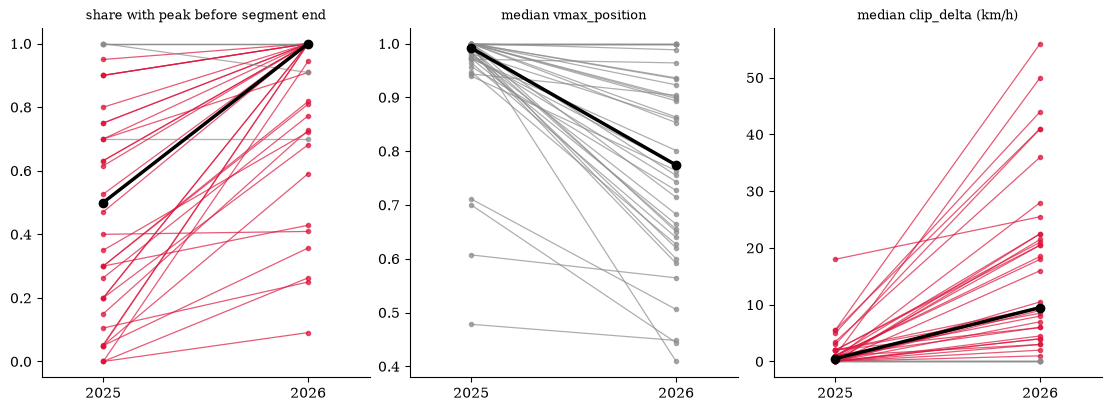

In [6]:
fig, axes = plt.subplots(1, len(METRICS), figsize=(11, 4), layout="constrained")
for ax, (m, label) in zip(axes, METRICS.items()):
    for s, r in per.iterrows():
        up = r[(m, 2026)] > r[(m, 2025)]
        ax.plot([0, 1], [r[(m, 2025)], r[(m, 2026)]], color="crimson" if up else "0.55", lw=0.9, alpha=0.7, marker="o", ms=3)
    ax.plot([0, 1], [per[(m, 2025)].median(), per[(m, 2026)].median()], color="black", lw=2.5, marker="o", ms=6)
    ax.set_xticks([0, 1], ["2025", "2026"])
    ax.set_xlim(-0.3, 1.3)
    ax.set_title(label, fontsize=9)
fig.savefig(FIG / "fig_regs_paired_straights.pdf")
plt.show()

In [7]:
caption("Figure", "paired", f"Paired straights, 2025 vs 2026 ({len(per)} straights): each line is one straight (red = higher in 2026, grey = lower or equal), "
        "black = median across straights. Panels: share of drivers whose peak comes before the segment end, median vmax_position, median clip_delta. "
        "Year differences reflect the whole 2026 package, not one rule. Descriptive.")

*Figure 1. Paired straights, 2025 vs 2026 (39 straights): each line is one straight (red = higher in 2026, grey = lower or equal), black = median across straights. Panels: share of drivers whose peak comes before the segment end, median vmax_position, median clip_delta. Year differences reflect the whole 2026 package, not one rule. Descriptive.*

## Suzuka: the straight through 130R, 2025 vs 2026

One clean lap per year: the fastest lap among each year's selected T14→T16 segments (freeze-free by selection). Speed is plotted against distance normalised along that segment (0 = segment start, 1 = segment end).

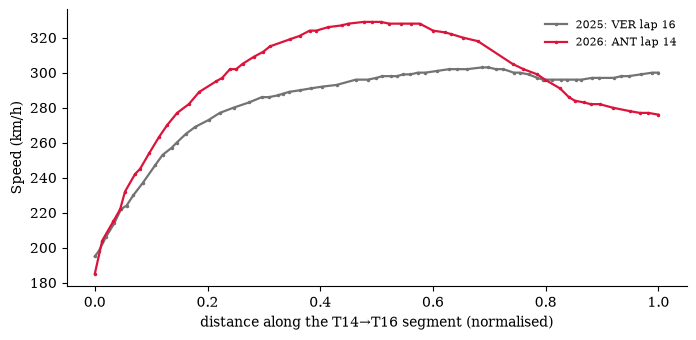

In [8]:
traces = {}
fig, ax = plt.subplots(figsize=(8, 3.6))
for year, out, rnd_col, color in [(2025, OUT25, "Round25", "0.45"), (2026, OUT26, "Round26", "crimson")]:
    rnd = int(pairs.loc[pairs.CircuitName == "Suzuka", rnd_col].iloc[0])
    s16 = pd.read_csv(next(out.glob(f"{rnd:02d}_*_segments.csv")))
    r = s16[(s16.Label == "T16") & ~s16.CrossesTimingLine].sort_values("LapTime_s").iloc[0]
    lap = load_quali(year, rnd).laps.pick_drivers(r.Driver).pick_laps(int(r.LapNumber)).iloc[0]
    car = lap.get_car_data().add_distance()
    car = car[car.Distance.between(r.start_m, r.end_m)]
    x = (car.Distance - r.start_m) / (r.end_m - r.start_m)
    ax.plot(x, car.Speed, color=color, lw=1.6, marker=".", ms=3, label=f"{year}: {r.Driver} lap {int(r.LapNumber)}")
    traces[year] = r
ax.set(xlabel="distance along the T14→T16 segment (normalised)", ylabel="Speed (km/h)")
ax.legend(frameon=False, fontsize=8)
fig.savefig(FIG / "fig_regs_suzuka_t16_traces.pdf")
plt.show()

In [9]:
caption("Figure", "suzuka", "Speed along the Suzuka T14→T16 straight (through 130R), fastest selected lap per year: " + "; ".join(
    f"{y} {r.Driver} lap {int(r.LapNumber)}: peak {r.peak_speed:.0f} km/h at vmax_position {r.vmax_position:.2f}, clip_delta {r.clip_delta:.0f} km/h"
    for y, r in traces.items()) + ". One lap per year; 2025 and 2026 cars differ in many ways (MGU-H, 120 kW MGU-K, DRS, aero). Descriptive.")

*Figure 2. Speed along the Suzuka T14→T16 straight (through 130R), fastest selected lap per year: 2025 VER lap 16: peak 303 km/h at vmax_position 0.70, clip_delta 3 km/h; 2026 ANT lap 14: peak 329 km/h at vmax_position 0.51, clip_delta 53 km/h. One lap per year; 2025 and 2026 cars differ in many ways (MGU-H, 120 kW MGU-K, DRS, aero). Descriptive.*